# Food Delivery Product Analytics: growth, delivery, retention and a free-delivery A/B test

**Business question:** what drives orders, GMV and on-time delivery across Riyadh, Jeddah and Dammam, and should a delivery platform lower the free-delivery threshold from SAR 75 to SAR 50?

**Data disclosure.** This is synthetic demonstration data, not internal company data. The base is the public Kaggle dataset *Food Delivery Operations and Customer Analytics* (deepeshkansotia): 15,000 realistic synthetic orders, 30 columns, money in USD. It was adapted to Saudi Arabia (2026 dates, three cities, SAR at 3.75 per USD, seeded customer / restaurant / rider IDs, app events, A/B assignment). The A/B treatment effect in Step 7 is **simulated** and labelled as such.

Run order: this notebook (Steps 2-4, 6-7) and `scripts/run_sql.py` (Step 5, live PostgreSQL). Restart and Run All.

## Step 2 - Data understanding

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
import duckdb

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"

In [3]:
raw = pd.read_csv("../data/raw/food_delivery.csv")

In [4]:
raw.shape

(15000, 30)

15,000 orders and 30 columns, exactly what the source documents. One row is one order.

In [5]:
raw.dtypes

order_id                              object
city_tier                              int64
customer_age                           int64
customer_loyalty_score               float64
order_hour                             int64
order_day_of_week                      int64
order_month                            int64
delivery_distance_km                 float64
preparation_time_minutes               int64
delivery_time_minutes                  int64
estimated_delivery_time                int64
traffic_level_score                  float64
weather_severity_score               float64
restaurant_rating                    float64
delivery_partner_rating              float64
customer_rating                      float64
order_value                          float64
delivery_fee                         float64
discount_amount                      float64
tip_amount                           float64
final_amount_paid                    float64
number_of_items                        int64
cancellati

Flags are real booleans, scores and money are floats, times are whole minutes. `order_id` is a UUID string. There is no date column, only month, day of week and hour.

In [6]:
raw.head(5)

,order_id,city_tier,customer_age,customer_loyalty_score,order_hour,order_day_of_week,order_month,delivery_distance_km,preparation_time_minutes,delivery_time_minutes,estimated_delivery_time,traffic_level_score,weather_severity_score,restaurant_rating,delivery_partner_rating,customer_rating,order_value,delivery_fee,discount_amount,tip_amount,final_amount_paid,number_of_items,cancellation_flag,delayed_delivery_flag,refund_flag,promo_code_used,premium_customer_flag,festival_or_weekend_flag,delivery_partner_experience_years,delivery_efficiency_score
0,5a87c6ab-e4a8-44ef-8852-f7a63e3b3943,2,21,4.957522,20,6,6,14.117144,23,76,68,5.4,2.6,4.3,4.1,2.9,100.000000,14.592602,22.969359,19.940541,111.563784,4,False,False,True,False,False,True,9,71.1
1,8eab78a5-a5c5-41d7-9a5f-5779ee5f2d3d,1,63,38.744721,0,2,2,9.177354,16,34,40,1.0,1.6,4.0,4.2,3.4,100.000000,4.391720,4.434405,16.101949,116.059264,7,False,False,False,True,False,False,12,100.0
2,1338cc5b-e5cf-419f-a7c9-4a2577608715,1,68,45.170997,9,2,11,34.753921,41,152,142,8.3,4.1,4.4,4.2,3.7,100.000000,9.006407,14.979691,17.681454,111.708170,12,False,False,False,False,False,False,10,34.4
3,5277f2fb-b1b3-4f58-9975-12f8f1b71421,2,30,10.573003,6,6,5,26.596184,9,93,93,3.2,8.8,4.8,4.6,4.1,145.113442,11.407034,14.813044,11.593912,153.301345,7,False,False,False,False,True,True,1,45.0
4,df159a97-3a78-4b08-a524-ec433c75b670,2,60,58.284620,12,1,9,26.204152,49,141,134,7.5,9.5,4.0,3.9,4.6,100.000000,11.572232,13.716308,13.272883,111.128807,2,True,False,False,False,False,False,6,25.1


`order_value` of exactly 100.0 appears in several rows. That is a floor in the source, examined below.

In [7]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
city_tier,15000.0,2.253133,0.827951,1.000000,2.000000,3.000000,3.000000,3.000000
customer_age,15000.0,46.569667,16.840706,18.000000,32.000000,46.000000,61.000000,75.000000
customer_loyalty_score,15000.0,50.017658,28.771665,0.007172,25.199828,50.092268,74.840432,99.989375
order_hour,15000.0,11.470933,6.946134,0.000000,5.000000,11.000000,18.000000,23.000000
order_day_of_week,15000.0,3.141933,1.809864,1.000000,1.000000,3.000000,5.000000,6.000000
order_month,15000.0,6.474667,3.454469,1.000000,3.000000,7.000000,9.000000,12.000000
delivery_distance_km,15000.0,20.133756,11.543488,0.103086,10.133190,20.228709,30.047891,39.998739
preparation_time_minutes,15000.0,32.749667,16.162719,5.000000,19.000000,33.000000,47.000000,60.000000
delivery_time_minutes,15000.0,94.139267,33.597132,10.000000,68.000000,95.000000,120.000000,180.000000
estimated_delivery_time,15000.0,94.140667,32.490455,11.000000,69.000000,94.000000,119.000000,178.000000


Delivery time runs 10 to 180 minutes (mean 94.1). `order_value` has min = median = 100, so more than half the baskets sit on a floor. Ratings are 1 to 5, scores 0 to 10 or 0 to 100.

In [8]:
checks = {
    "rows == 15000": len(raw) == 15000,
    "cols == 30": raw.shape[1] == 30,
    "months 1..12": sorted(raw.order_month.unique()) == list(range(1, 13)),
    "city_tier 1..3": sorted(raw.city_tier.unique()) == [1, 2, 3],
    "cancelled == 2003": int(raw.cancellation_flag.sum()) == 2003,
    "delivery mean ~94.1": round(raw.delivery_time_minutes.mean(), 1) == 94.1,
}
assert all(checks.values()), checks
checks

{'rows == 15000': True,
 'cols == 30': True,
 'months 1..12': True,
 'city_tier 1..3': True,
 'cancelled == 2003': True,
 'delivery mean ~94.1': True}

Every known number matches, so this is the right file.

In [9]:
raw.isna().sum()[raw.isna().sum() > 0]

delivery_partner_rating    150
customer_rating            150
tip_amount                 150
dtype: int64

Only three columns have nulls, 150 each. No column is all null.

In [10]:
(raw.order_value == 100).mean().round(4), raw.order_value.min()

(0.5974, 100.0)

59.7% of baskets are exactly USD 100 and none are below it. The source clipped `order_value` at 100, so AOV is inflated and basket-size analysis has a hard floor.

In [11]:
(raw.discount_amount > 0).mean(), raw.promo_code_used.mean().round(4)

(1.0, 0.4231)

Every order carries a positive `discount_amount`, but only 42.3% used a promo code. So "discounted vs not" must be read from `promo_code_used`, not from the discount column.

## Step 3 - Saudi adaptation

The adapted table `orders_clean_sa.csv` was produced by a seeded generator (seed 42) that ships with the dataset pack.
The deterministic parts are **rebuilt here from raw and compared column by column**. The seeded parts (IDs, day of
month, device, A/B group) are checked for the properties the design requires.

In [12]:
CITY_BY_TIER = {1: "Riyadh", 2: "Jeddah", 3: "Dammam"}
USD_TO_SAR = 3.75
MONEY = ["order_value", "delivery_fee", "discount_amount", "tip_amount", "final_amount_paid"]

In [13]:
rebuilt = raw.copy()
rebuilt["city"] = rebuilt.city_tier.map(CITY_BY_TIER)
for col in MONEY:
    rebuilt[f"{col}_sar"] = (rebuilt[col] * USD_TO_SAR).round(2)
rebuilt[["order_id", "city_tier", "city"] + [f"{c}_sar" for c in MONEY]].head(3)

,order_id,city_tier,city,order_value_sar,delivery_fee_sar,discount_amount_sar,tip_amount_sar,final_amount_paid_sar
0,5a87c6ab-e4a8-44ef-8852-f7a63e3b3943,2,Jeddah,375.0,54.72,86.14,74.78,418.36
1,8eab78a5-a5c5-41d7-9a5f-5779ee5f2d3d,1,Riyadh,375.0,16.47,16.63,60.38,435.22
2,1338cc5b-e5cf-419f-a7c9-4a2577608715,1,Riyadh,375.0,33.77,56.17,66.31,418.91


In [14]:
orders = pd.read_csv("../data/processed/orders_clean_sa.csv", parse_dates=["order_date", "order_datetime"])
orders.shape

(15000, 41)

The clean table keeps all 15,000 rows and grows to 41 columns: the original operational columns plus date, city, SAR money and seeded IDs. The USD money columns are replaced by `_sar` columns, one currency everywhere.

In [15]:
same_order = (orders.order_id.values == rebuilt.order_id.values).all()
city_ok = (orders.city.values == rebuilt.city.values).all()
money_gap = {c: float(np.nanmax(np.abs(orders[f"{c}_sar"].values - rebuilt[f"{c}_sar"].values))) for c in MONEY}
assert same_order and city_ok and max(money_gap.values()) == 0
same_order, city_ok, money_gap

(True,
 True,
 {'order_value': 0.0,
  'delivery_fee': 0.0,
  'discount_amount': 0.0,
  'tip_amount': 0.0,
  'final_amount_paid': 0.0})

Row order, city mapping and all five SAR conversions reproduce exactly from raw (max gap 0.00 SAR).

In [16]:
untouched = [c for c in raw.columns if c in orders.columns]
diffs = {c: int((~((orders[c] == raw[c]) | (orders[c].isna() & raw[c].isna()))).sum()) for c in untouched}
assert sum(diffs.values()) == 0
len(untouched), sum(diffs.values())

(25, 0)

All 25 operational columns that pass through unchanged are identical to raw. The adaptation did not edit any source value.

In [17]:
mapping = (orders.groupby(["city_tier", "city"]).size().rename("orders").reset_index())
mapping["rule"] = "tier 1 = Riyadh, tier 2 = Jeddah, tier 3 = Dammam (3 cities only, no invented 4th city)"
mapping.to_csv("../data/processed/saudi_mapping.csv", index=False)
mapping

,city_tier,city,orders,rule
0,1,Riyadh,3723,"tier 1 = Riyadh, tier 2 = Jeddah, tier 3 = Dam..."
1,2,Jeddah,3757,"tier 1 = Riyadh, tier 2 = Jeddah, tier 3 = Dam..."
2,3,Dammam,7520,"tier 1 = Riyadh, tier 2 = Jeddah, tier 3 = Dam..."


Dammam carries 7,520 orders because tier 3 is the largest tier in the source. The mapping is kept literal rather than reshuffled to make Riyadh look biggest, and the README says so.

In [18]:
date_checks = {
    "year is 2026": bool((orders.order_date.dt.year == 2026).all()),
    "month matches order_month": bool((orders.order_date.dt.month == orders.order_month).all()),
    "weekday matches order_day_of_week": float((orders.order_date.dt.dayofweek == orders.order_day_of_week).mean().round(3)),
}
date_checks

{'year is 2026': True,
 'month matches order_month': True,
 'weekday matches order_day_of_week': 0.143}

Year and month are right. The seeded day of month does **not** honour `order_day_of_week` (only 14% agree, about 1 in 7 by chance). So weekday analysis uses the source `order_day_of_week` column, not `order_date`.

In [19]:
id_checks = {
    "distinct customers": orders.customer_id.nunique(),
    "distinct restaurants": orders.restaurant_id.nunique(),
    "distinct riders": orders.delivery_partner_id.nunique(),
    "max ab groups per customer": int(orders.groupby("customer_id").ab_group.nunique().max()),
    "max cities per customer": int(orders.groupby("customer_id").city.nunique().max()),
}
id_checks

{'distinct customers': 7309,
 'distinct restaurants': 350,
 'distinct riders': 800,
 'max ab groups per customer': 1,
 'max cities per customer': 3}

7,309 customers, so repeat orders exist (not one customer per order). Each customer stays in one A/B group. A customer can appear in up to 3 cities, which is a seeding artefact to remember when reading city-level retention.

In [20]:
events = pd.read_json("../data/processed/events.json", lines=True, dtype={"order_id": str})
events = pd.concat([events.drop(columns="payload"), pd.json_normalize(events.payload).add_prefix("payload.")], axis=1)
events.shape

(60000, 12)

In [21]:
events.head(8)

,order_id,customer_id,event_type,event_time,device,city,payload.items_viewed,payload.items,payload.promo_code_used,payload.ab_threshold_sar,payload.delivery_time_minutes,payload.reason
0,5a87c6ab-e4a8-44ef-8852-f7a63e3b3943,CUST-00804,browse,2026-06-02 19:25:00,Android,Jeddah,6.0,NaN,NaN,NaN,NaN,NaN
1,5a87c6ab-e4a8-44ef-8852-f7a63e3b3943,CUST-00804,add_to_cart,2026-06-02 19:40:00,Android,Jeddah,NaN,4.0,NaN,NaN,NaN,NaN
2,5a87c6ab-e4a8-44ef-8852-f7a63e3b3943,CUST-00804,checkout,2026-06-02 20:00:00,Android,Jeddah,NaN,NaN,False,75.0,NaN,NaN
3,5a87c6ab-e4a8-44ef-8852-f7a63e3b3943,CUST-00804,delivered,2026-06-02 21:16:00,Android,Jeddah,NaN,NaN,NaN,NaN,76.0,NaN
4,8eab78a5-a5c5-41d7-9a5f-5779ee5f2d3d,CUST-06966,browse,2026-02-03 23:25:00,iOS,Riyadh,9.0,NaN,NaN,NaN,NaN,NaN
5,8eab78a5-a5c5-41d7-9a5f-5779ee5f2d3d,CUST-06966,add_to_cart,2026-02-03 23:40:00,iOS,Riyadh,NaN,7.0,NaN,NaN,NaN,NaN
6,8eab78a5-a5c5-41d7-9a5f-5779ee5f2d3d,CUST-06966,checkout,2026-02-04 00:00:00,iOS,Riyadh,NaN,NaN,True,75.0,NaN,NaN
7,8eab78a5-a5c5-41d7-9a5f-5779ee5f2d3d,CUST-06966,delivered,2026-02-04 00:34:00,iOS,Riyadh,NaN,NaN,NaN,NaN,34.0,NaN


Each event is one line of JSON. The nested `payload` is flattened with `json_normalize`, and each event type fills different payload keys (items viewed, cart items, promo and threshold at checkout, delivery minutes).

In [22]:
events.event_type.value_counts()

event_type
browse         15000
add_to_cart    15000
checkout       15000
delivered      12997
cancelled       2003
Name: count, dtype: int64

In [23]:
per_order = events.groupby("order_id").size()
in_time_order = events.groupby("order_id").event_time.apply(lambda s: s.is_monotonic_increasing).all()
per_order.value_counts(), in_time_order

(4    15000
 Name: count, dtype: int64,
 True)

60,000 events: exactly 4 per order, always in time order. Every order goes browse -> add_to_cart -> checkout -> delivered or cancelled. So the funnel has **no drop-off before checkout** (sessions that never bought are not in the data). Only the last step carries information.

## Step 4 - Data quality, cleaning and quarantine

In [24]:
dq = []
def rule(name, checked, failed, action):
    dq.append({"rule": name, "rows_checked": int(checked), "rows_failed": int(failed), "action": action})
    return failed

In [25]:
rule('duplicate_order_id', len(orders), orders.order_id.duplicated().sum(), 'quarantine')

0

In [26]:
rule('null_order_id', len(orders), orders.order_id.isna().sum(), 'quarantine')

0

In [27]:
orders.isna().sum()[orders.isna().sum() > 0]

delivery_partner_rating    150
customer_rating            150
tip_amount_sar             150
dtype: int64

In [28]:
rule('delivery_time_outside_0_300', len(orders), (~orders.delivery_time_minutes.between(0, 300)).sum(), 'quarantine')

0

In [29]:
rule('negative_preparation_time', len(orders), (orders.preparation_time_minutes < 0).sum(), 'quarantine')

0

In [30]:
rule('negative_order_value', len(orders), (orders.order_value_sar < 0).sum(), 'quarantine')

0

In [31]:
rule('negative_distance', len(orders), (orders.delivery_distance_km < 0).sum(), 'quarantine')

0

In [32]:
rule('order_date_outside_2026', len(orders), (orders.order_date.dt.year != 2026).sum(), 'quarantine')

0

In [33]:
has_tip = orders.tip_amount_sar.notna()
identity_gap = (orders.order_value_sar + orders.delivery_fee_sar - orders.discount_amount_sar
                + orders.tip_amount_sar - orders.final_amount_paid_sar).abs()
rule('payment_identity_gap_gt_1_sar', has_tip.sum(), (identity_gap[has_tip] > 1).sum(), 'quarantine')

0

`final_amount_paid = order_value + delivery_fee - discount + tip` holds within 1 SAR on all 14,850 rows that have a tip.

In [34]:
null_tip = orders[orders.tip_amount_sar.isna()]
paid_minus_known = null_tip.final_amount_paid_sar - (null_tip.order_value_sar + null_tip.delivery_fee_sar - null_tip.discount_amount_sar)
pd.Series({"null-tip rows": len(null_tip),
           "of which cancelled": int(null_tip.cancellation_flag.sum()),
           "paid exceeds basket+fee-discount by > 1 SAR": int((paid_minus_known > 1).sum())})

null-tip rows                                  150
of which cancelled                              19
paid exceeds basket+fee-discount by > 1 SAR    148
dtype: int64

**Correction to the dataset notes.** The pack's README says the 150 null ratings / tips *are the cancelled orders*.
They are not: only 19 of the 150 are cancelled. And in 148 of them `final_amount_paid` is more than 1 SAR above basket + fee - discount, so a tip, was
paid but its value is **missing**, not zero. Action: keep them null (filling 0 would understate tips), and
exclude them from tip and rating averages. No hard rule fails, so nothing is quarantined.

In [35]:
rule('null_tip_amount', len(orders), orders.tip_amount_sar.isna().sum(), 'keep null, flag')
rule('null_customer_rating', len(orders), orders.customer_rating.isna().sum(), 'keep null, flag')
rule('null_delivery_partner_rating', len(orders), orders.delivery_partner_rating.isna().sum(), 'keep null, flag')
dq_summary = pd.DataFrame(dq).sort_values("rule").reset_index(drop=True)
dq_summary

,rule,rows_checked,rows_failed,action
0,delivery_time_outside_0_300,15000,0,quarantine
1,duplicate_order_id,15000,0,quarantine
2,negative_distance,15000,0,quarantine
3,negative_order_value,15000,0,quarantine
4,negative_preparation_time,15000,0,quarantine
5,null_customer_rating,15000,150,"keep null, flag"
6,null_delivery_partner_rating,15000,150,"keep null, flag"
7,null_order_id,15000,0,quarantine
8,null_tip_amount,15000,150,"keep null, flag"
9,order_date_outside_2026,15000,0,quarantine


In [36]:
hard = dq_summary[dq_summary.action == "quarantine"]
quarantine = pd.DataFrame(columns=["order_id", "rule", "bad_value"])
quarantine.to_csv("../data/processed/quarantine_log.csv", index=False)
clean = orders.copy()
assert len(raw) == len(clean) + len(quarantine)
f"raw {len(raw):,} = clean {len(clean):,} + quarantined {len(quarantine):,}", int(hard.rows_failed.sum())

('raw 15,000 = clean 15,000 + quarantined 0', 0)

Raw 15,000 = clean 15,000 + quarantined 0. The quarantine log is empty because no row fails any of the 8 hard rules, not because rows were deleted.

In [37]:
dq_summary.to_csv("../reports/dq_summary.csv", index=False)
len(dq_summary)

11

## Step 5 - SQL layer, DuckDB mirror of the BigQuery files

Each `sql/bigquery/*.sql` file runs in DuckDB with three tiny shims (`COUNTIF`, `SAFE_DIVIDE`, `JSON_VALUE`, plus a
`FLOAT64` type alias), so the BigQuery text is not edited. Results are compared to pandas. If they disagree, the
SQL gets fixed, not the pandas. The live PostgreSQL run and the Redshift port check are in `scripts/run_sql.py`.

In [38]:
con = duckdb.connect()
con.execute("CREATE SCHEMA food_delivery")
con.execute("CREATE TABLE food_delivery.orders AS SELECT * FROM read_csv('../data/processed/orders_clean_sa.csv', header=true, "
            "types={'order_date': 'DATE', 'tip_amount_sar': 'DOUBLE', 'customer_rating': 'DOUBLE', 'delivery_partner_rating': 'DOUBLE'})")
con.execute("CREATE TABLE food_delivery.events AS SELECT * FROM read_json('../data/processed/events.json', format='newline_delimited', "
            "columns={'order_id': 'VARCHAR', 'customer_id': 'VARCHAR', 'event_type': 'VARCHAR', 'event_time': 'TIMESTAMP', "
            "'device': 'VARCHAR', 'city': 'VARCHAR', 'payload': 'JSON'})")
con.execute("""
CREATE TYPE float64 AS DOUBLE;
CREATE MACRO countif(x) AS count_if(x);
CREATE MACRO safe_divide(a, b) AS CASE WHEN b = 0 THEN NULL ELSE a / b END;
CREATE MACRO json_value(j, p) AS json_extract_string(j, p);
""")
con.execute("SELECT COUNT(*) FROM food_delivery.orders").fetchone(), con.execute("SELECT COUNT(*) FROM food_delivery.events").fetchone()

((15000,), (60000,))

In [39]:
def bq(name):
    return con.execute(open(f"../sql/bigquery/{name}.sql", encoding="utf-8").read()).df()

In [40]:
sql_dq = bq("01_data_quality")
cols = ["rule", "rows_checked", "rows_failed"]
assert (sql_dq[cols].astype({"rows_checked": int, "rows_failed": int}).values == dq_summary[cols].values).all()
sql_dq

,rule,rows_checked,rows_failed,action
0,delivery_time_outside_0_300,15000.0,0.0,quarantine
1,duplicate_order_id,15000.0,0.0,quarantine
2,negative_distance,15000.0,0.0,quarantine
3,negative_order_value,15000.0,0.0,quarantine
4,negative_preparation_time,15000.0,0.0,quarantine
5,null_customer_rating,15000.0,150.0,"keep null, flag"
6,null_delivery_partner_rating,15000.0,150.0,"keep null, flag"
7,null_order_id,15000.0,0.0,quarantine
8,null_tip_amount,15000.0,150.0,"keep null, flag"
9,order_date_outside_2026,15000.0,0.0,quarantine


In [41]:
delivered = clean[~clean.cancellation_flag]
repeat = clean.groupby("customer_id").size()
kpi_pandas = pd.Series({
    "orders": len(clean),
    "delivered_orders": len(delivered),
    "cancelled_orders": int(clean.cancellation_flag.sum()),
    "cancellation_rate": clean.cancellation_flag.mean(),
    "gmv_sar": delivered.final_amount_paid_sar.sum(),
    "aov_sar": delivered.final_amount_paid_sar.mean(),
    "on_time_rate": 1 - delivered.delayed_delivery_flag.mean(),
    "avg_delivery_min": delivered.delivery_time_minutes.mean(),
    "refunds": int(clean.refund_flag.sum()),
    "customers": clean.customer_id.nunique(),
    "orders_per_customer": len(clean) / clean.customer_id.nunique(),
    "repeat_rate": (repeat > 1).mean(),
})
kpi_pandas.round(4)

orders                 1.500000e+04
delivered_orders       1.299700e+04
cancelled_orders       2.003000e+03
cancellation_rate      1.335000e-01
gmv_sar                5.797901e+06
aov_sar                4.460953e+02
on_time_rate           9.051000e-01
avg_delivery_min       9.387870e+01
refunds                6.180000e+02
customers              7.309000e+03
orders_per_customer    2.052300e+00
repeat_rate            6.073000e-01
dtype: float64

In [42]:
kpi_sql = bq("02_kpi_scorecard").set_index("metric")["value"]
kpi_compare = pd.DataFrame({"pandas": kpi_pandas, "duckdb_bigquery_sql": kpi_sql})
kpi_compare["abs_diff"] = (kpi_compare.pandas - kpi_compare.duckdb_bigquery_sql).abs()
assert (kpi_compare.abs_diff < 0.006).all()
kpi_compare

,pandas,duckdb_bigquery_sql,abs_diff
aov_sar,4.460953e+02,4.461000e+02,0.004703
avg_delivery_min,9.387874e+01,9.388000e+01,0.001259
cancellation_rate,1.335333e-01,1.335000e-01,0.000033
cancelled_orders,2.003000e+03,2.003000e+03,0.000000
customers,7.309000e+03,7.309000e+03,0.000000
delivered_orders,1.299700e+04,1.299700e+04,0.000000
gmv_sar,5.797901e+06,5.797901e+06,0.000000
on_time_rate,9.050550e-01,9.051000e-01,0.000045
orders,1.500000e+04,1.500000e+04,0.000000
orders_per_customer,2.052264e+00,2.052300e+00,0.000036


All 12 KPIs agree to rounding. GMV SAR 5,797,900.58 and AOV SAR 446.10 are on delivered orders. Delivery time is
93.88 minutes on delivered orders (94.14 if cancelled rows are included, which is how the pack's summary was computed).
On-time rate is 90.51% of delivered orders.

In [43]:
funnel_sql = bq("03_funnel")
funnel_pd = (events.assign(delivered=events.event_type.eq("delivered")).groupby(["city", "device"])
             .agg(checkout_sessions=("event_type", lambda s: (s == "checkout").sum()), delivered_sessions=("delivered", "sum"))
             .reset_index())
assert (funnel_sql[["checkout_sessions", "delivered_sessions"]].astype(int).values == funnel_pd[["checkout_sessions", "delivered_sessions"]].values).all()
funnel_sql

,city,device,browse_sessions,cart_sessions,checkout_sessions,delivered_sessions,browse_to_cart,cart_to_checkout,checkout_to_delivered,promo_share_at_checkout
0,Dammam,Android,3438.0,3438.0,3438.0,3010.0,1.0,1.0,0.8755,0.4287
1,Dammam,Web,746.0,746.0,746.0,638.0,1.0,1.0,0.8552,0.4276
2,Dammam,iOS,3336.0,3336.0,3336.0,2880.0,1.0,1.0,0.8633,0.4236
3,Jeddah,Android,1706.0,1706.0,1706.0,1471.0,1.0,1.0,0.8623,0.4226
4,Jeddah,Web,363.0,363.0,363.0,312.0,1.0,1.0,0.8595,0.4187
5,Jeddah,iOS,1688.0,1688.0,1688.0,1468.0,1.0,1.0,0.8697,0.4141
6,Riyadh,Android,1659.0,1659.0,1659.0,1426.0,1.0,1.0,0.8596,0.4340
7,Riyadh,Web,362.0,362.0,362.0,315.0,1.0,1.0,0.8702,0.3950
8,Riyadh,iOS,1702.0,1702.0,1702.0,1477.0,1.0,1.0,0.8678,0.4148


In [44]:
growth_sql = bq("04_growth")
month_pd = delivered.groupby("order_month").final_amount_paid_sar.sum().round(2)
assert np.allclose(growth_sql.query("dimension == 'month'").gmv_sar.values, month_pd.values)
retention_sql = bq("06_retention")
ab_sql = bq("07_ab_scorecard")
delivery_sql = bq("05_delivery")
"BigQuery files 01-07 checked against pandas"

'BigQuery files 01-07 checked against pandas'

In [45]:
pd.read_csv("../reports/sql_outputs/parity.csv")

,query,rows,bigquery_duckdb_vs_postgres,postgres_vs_redshift_port
0,01_data_quality,11,True,True
1,02_kpi_scorecard,12,True,True
2,03_funnel,9,True,True
3,04_growth,51,True,True
4,05_delivery,56,True,True
5,06_retention,78,True,True
6,07_ab_scorecard,2,True,True


`scripts/run_sql.py` loaded the same files into a live local PostgreSQL 16 server (15,000 orders, 60,000 events). All 7 queries return the same result in DuckDB (BigQuery dialect), PostgreSQL, and the Redshift-port files run on PostgreSQL.

## Step 6 - Growth, delivery and retention analysis

### Growth

In [46]:
monthly = (clean.groupby("order_month")
           .agg(orders=("order_id", "size"),
                delivered=("cancellation_flag", lambda s: (~s).sum()))
           .join(delivered.groupby("order_month").final_amount_paid_sar.sum().rename("gmv_sar")))
monthly["mom_gmv_growth"] = monthly.gmv_sar.pct_change()
monthly.round(4)

,orders,delivered,gmv_sar,mom_gmv_growth
order_month,,,,
1,1289,1104,491102.51,NaN
2,1257,1084,482418.84,-0.0177
3,1270,1094,488525.63,0.0127
4,1210,1050,469838.34,-0.0383
5,1242,1080,486622.17,0.0357
6,1230,1080,483142.24,-0.0072
7,1266,1094,482748.47,-0.0008
8,1295,1108,498020.77,0.0316
9,1255,1090,486312.82,-0.0235


In [47]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(monthly.index, monthly.orders, color="#f2b705", label="orders")
ax1.set_xlabel("month (2026)"); ax1.set_ylabel("orders"); ax1.set_xticks(range(1, 13))
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly.gmv_sar / 1e3, color="#d62828", marker="o", label="GMV (SAR k)")
ax2.set_ylabel("GMV, SAR thousand (delivered)")
ax1.set_title("Monthly orders and GMV - flat within about +/-3%")
fig.tight_layout(); fig.savefig(FIG + "01_monthly_orders_gmv.png", dpi=120)

(8, 498020.77, 4, 469838.34, 0.06)

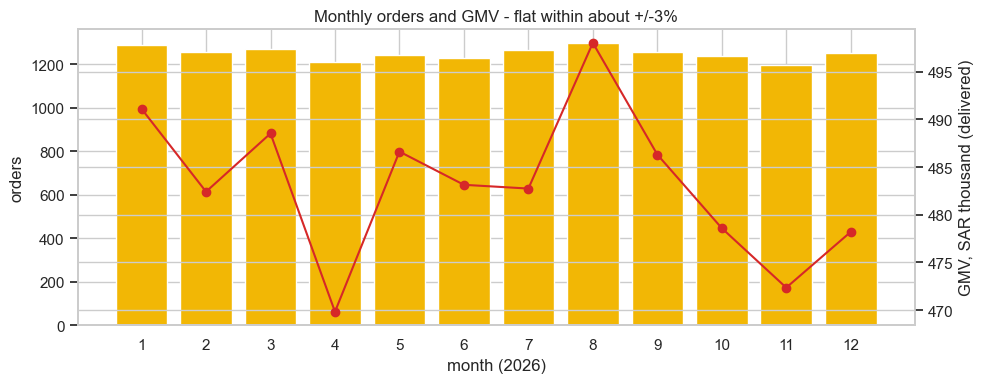

In [48]:
best, worst = monthly.gmv_sar.idxmax(), monthly.gmv_sar.idxmin()
spread = monthly.gmv_sar.max() / monthly.gmv_sar.min() - 1
best, round(monthly.gmv_sar.max(), 2), worst, round(monthly.gmv_sar.min(), 2), round(spread, 4)

Best month is August (SAR 498,021), worst is April (SAR 469,838), a 6.0% spread. There is no seasonality or trend in this synthetic base, so month-over-month growth is noise around flat.

In [49]:
city = (clean.groupby("city").agg(orders=("order_id", "size"))
        .join(delivered.groupby("city").agg(gmv_sar=("final_amount_paid_sar", "sum"), aov_sar=("final_amount_paid_sar", "mean"))))
city["gmv_share"] = city.gmv_sar / city.gmv_sar.sum()
city.sort_values("orders", ascending=False).round(2)

,orders,gmv_sar,aov_sar,gmv_share
city,,,,
Dammam,7520,2916666.26,446.79,0.50
Jeddah,3757,1444841.10,444.43,0.25
Riyadh,3723,1436393.22,446.36,0.25


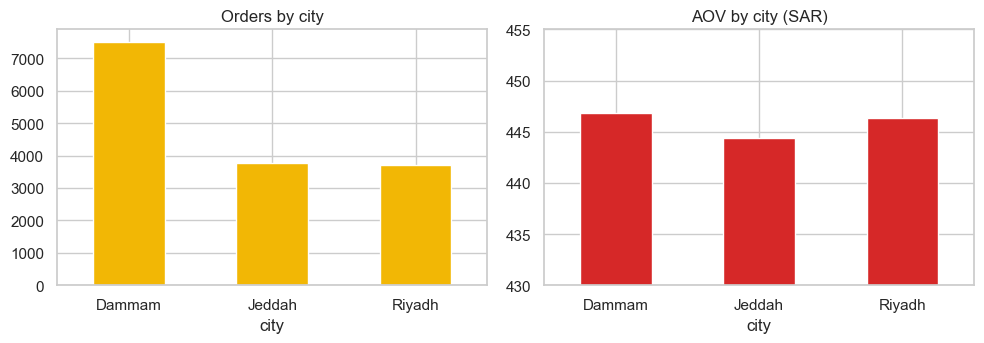

In [50]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
city.orders.plot.bar(ax=ax[0], color="#f2b705", title="Orders by city")
city.aov_sar.plot.bar(ax=ax[1], color="#d62828", title="AOV by city (SAR)", ylim=(430, 455))
for a in ax: a.tick_params(axis="x", rotation=0)
fig.tight_layout(); fig.savefig(FIG + "02_city_orders_aov.png", dpi=120)

Dammam has the most orders (7,520, 50.3% of GMV) and the highest AOV (SAR 446.79), but AOV differs by only SAR 2.36 across cities. Volume, not basket, separates the cities.

In [51]:
promo = delivered.groupby("promo_code_used").agg(orders=("order_id", "size"), aov_sar=("final_amount_paid_sar", "mean"),
                                               basket_sar=("order_value_sar", "mean"), items=("number_of_items", "mean"))
promo_t = stats.ttest_ind(delivered.loc[delivered.promo_code_used, "final_amount_paid_sar"],
                          delivered.loc[~delivered.promo_code_used, "final_amount_paid_sar"], equal_var=False)
promo.round(2), round(promo_t.pvalue, 3)

(                 orders  aov_sar  basket_sar  items
 promo_code_used                                    
 False              7509   446.32      427.05   6.50
 True               5488   445.78      426.84   6.52,
 0.753)

Promo-code orders do not grow the basket: AOV SAR 445.78 vs 446.32 without a promo (Welch p = 0.75), same items per order. A promo budget is not buying bigger baskets here.

In [52]:
segment = delivered.groupby("premium_customer_flag").agg(orders=("order_id", "size"), aov_sar=("final_amount_paid_sar", "mean"))
segment["aov_uplift_vs_regular"] = segment.aov_sar / segment.loc[False, "aov_sar"] - 1
segment.round(4)

,orders,aov_sar,aov_uplift_vs_regular
premium_customer_flag,,,
False,9318,431.9703,0.0000
True,3679,481.8705,0.1155


Premium customers spend SAR 481.87 per order vs SAR 431.97 for regular customers, +11.6%. They place 28.3% of delivered orders.

In [53]:
hourly = delivered.groupby("order_hour").agg(orders=("order_id", "size"), gmv_sar=("final_amount_paid_sar", "sum"))
hourly.orders.agg(["min", "max", "mean"]).round(1)

min     501.0
max     568.0
mean    541.5
Name: orders, dtype: float64

Orders are spread evenly over 24 hours (501 to 568 delivered orders per hour). Real delivery apps peak at lunch and dinner. This flatness is a property of the synthetic base, so it is not used to plan rider shifts.

In [54]:
cuisine = delivered.groupby("cuisine").agg(orders=("order_id", "size"), gmv_sar=("final_amount_paid_sar", "sum"),
                                          aov_sar=("final_amount_paid_sar", "mean")).sort_values("gmv_sar", ascending=False)
cuisine.round(2)

,orders,gmv_sar,aov_sar
cuisine,,,
Pizza,1328,591882.21,445.69
Asian,1321,591828.53,448.02
Burgers,1319,589315.47,446.79
Desserts,1313,585017.24,445.56
Indian,1308,583107.01,445.80
Seafood,1303,582059.54,446.71
Shawarma,1279,573241.69,448.20
Healthy,1286,571694.37,444.55
Chicken,1269,565819.71,445.88


The 10 cuisines each hold about 10% of GMV (9.7% to 10.2%). No cuisine is a growth lever on its own in this data.

### Delivery and operations

In [55]:
delivery_by_city = delivered.groupby("city").agg(avg_delivery_min=("delivery_time_minutes", "mean"),
                                                 late_rate=("delayed_delivery_flag", "mean"))
delivery_by_city.round(4)

,avg_delivery_min,late_rate
city,,
Dammam,94.1146,0.0968
Jeddah,93.1904,0.0920
Riyadh,94.0957,0.0942


In [56]:
bands = delivered.assign(
    weather_band=pd.cut(delivered.weather_severity_score, [0, 2, 4, 6, 8, 10.01], right=False, labels=["0-2", "2-4", "4-6", "6-8", "8-10"]),
    traffic_band=pd.cut(delivered.traffic_level_score, [0, 2, 4, 6, 8, 10.01], right=False, labels=["0-2", "2-4", "4-6", "6-8", "8-10"]),
    prep_band=pd.cut(delivered.preparation_time_minutes, [0, 15, 25, 35, 100], right=False, labels=["<15", "15-24", "25-34", "35+"]),
    distance_band=pd.cut(delivered.delivery_distance_km, [0, 10, 20, 30, 40.01], right=False, labels=["<10", "10-20", "20-30", "30-40"]),
)
factor_rows = []
for factor in ["weather_band", "traffic_band", "prep_band", "distance_band"]:
    g = bands.groupby(factor, observed=True).agg(avg_delivery_min=("delivery_time_minutes", "mean"), late_rate=("delayed_delivery_flag", "mean"))
    factor_rows.append({"factor": factor,
                        "late_rate_min": g.late_rate.min(), "late_rate_max": g.late_rate.max(),
                        "late_rate_range_pp": (g.late_rate.max() - g.late_rate.min()) * 100,
                        "delivery_min_range": g.avg_delivery_min.max() - g.avg_delivery_min.min()})
factors = pd.DataFrame(factor_rows).sort_values("delivery_min_range", ascending=False)
factors.round(3)

,factor,late_rate_min,late_rate_max,late_rate_range_pp,delivery_min_range
3,distance_band,0.087,0.103,1.631,75.117
2,prep_band,0.081,0.099,1.833,31.041
1,traffic_band,0.090,0.103,1.205,15.855
0,weather_band,0.086,0.104,1.822,12.002


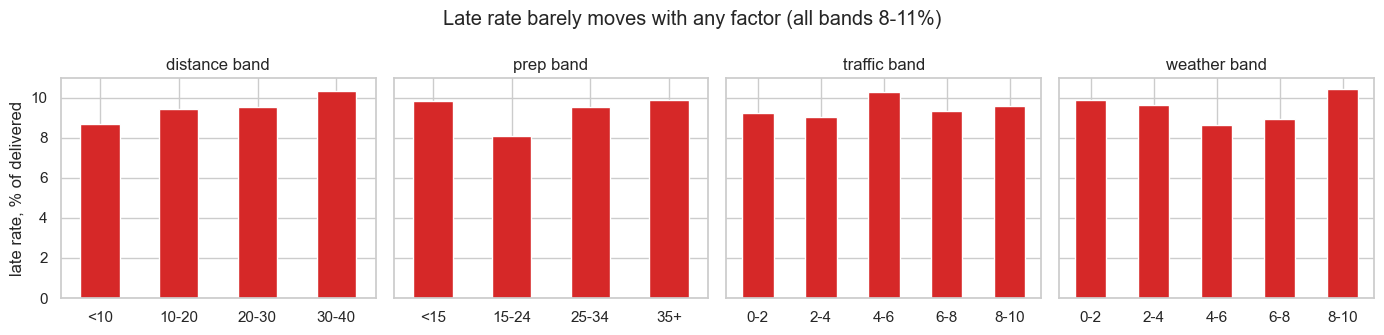

In [57]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for a, factor in zip(axes, ["distance_band", "prep_band", "traffic_band", "weather_band"]):
    bands.groupby(factor, observed=True).delayed_delivery_flag.mean().mul(100).plot.bar(ax=a, color="#d62828")
    a.set_title(factor.replace("_", " ")); a.set_xlabel(""); a.tick_params(axis="x", rotation=0)
axes[0].set_ylabel("late rate, % of delivered")
fig.suptitle("Late rate barely moves with any factor (all bands 8-11%)")
fig.tight_layout(); fig.savefig(FIG + "03_late_rate_by_factor.png", dpi=120)

In [58]:
drivers = delivered[["delivery_time_minutes", "delivery_distance_km", "preparation_time_minutes",
                     "traffic_level_score", "weather_severity_score"]].corr()["delivery_time_minutes"].drop("delivery_time_minutes")
drivers.round(3)

delivery_distance_km        0.863
preparation_time_minutes    0.395
traffic_level_score         0.161
weather_severity_score      0.134
Name: delivery_time_minutes, dtype: float64

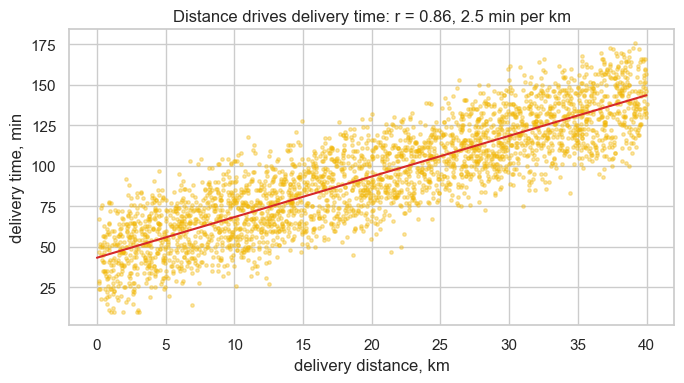

In [59]:
fig, ax = plt.subplots(figsize=(7, 4))
sample = delivered.sample(3000, random_state=42)
ax.scatter(sample.delivery_distance_km, sample.delivery_time_minutes, s=6, alpha=0.35, color="#f2b705")
fit = np.polyfit(delivered.delivery_distance_km, delivered.delivery_time_minutes, 1)
xs = np.linspace(0, 40, 50); ax.plot(xs, np.polyval(fit, xs), color="#d62828")
ax.set_xlabel("delivery distance, km"); ax.set_ylabel("delivery time, min")
ax.set_title(f"Distance drives delivery time: r = {drivers['delivery_distance_km']:.2f}, {fit[0]:.1f} min per km")
fig.tight_layout(); fig.savefig(FIG + "04_distance_vs_delivery_time.png", dpi=120)

Distance explains delivery time (r = 0.86, about 2.5 min per km), then prep time (r = 0.39). Traffic and weather add little (r = 0.16 and 0.13). But the **late flag** does not follow any of them: its range across bands is under 2.5 pp.

In [60]:
eta_breach = (clean.delivery_time_minutes > clean.estimated_delivery_time)
pd.crosstab(eta_breach.rename("actual > ETA"), clean.delayed_delivery_flag.rename("delayed_flag"), margins=True)

delayed_flag,False,True,All
actual > ETA,,,
False,7835,0,7835
True,5745,1420,7165
All,13580,1420,15000


This explains it. 7,165 orders (47.8%) arrived after their ETA, but only 1,420 carry `delayed_delivery_flag`, and the flag is never set on an on-time order. The flag is a subset with no rule we can recover, so it is a weak SLA metric. **Next step:** report ETA breach (actual > estimated) next to the source flag, and agree one definition with Logistics.

In [61]:
restaurants = (delivered.groupby(["restaurant_id", "restaurant_name", "cuisine"])
               .agg(orders=("order_id", "size"), gmv_sar=("final_amount_paid_sar", "sum"), avg_rating=("restaurant_rating", "mean"))
               .reset_index())
restaurants.nlargest(10, "gmv_sar").round(2)

,restaurant_id,restaurant_name,cuisine,orders,gmv_sar,avg_rating
145,REST-0146,Jeddah Shawarma 0146,Shawarma,52,24548.20,4.01
275,REST-0276,Dammam Shawarma 0276,Shawarma,53,24515.52,4.20
141,REST-0142,Riyadh Burgers 0142,Burgers,56,24190.25,4.15
212,REST-0213,Dammam Pizza 0213,Pizza,53,23371.45,4.22
273,REST-0274,Jeddah Indian 0274,Indian,51,22866.47,4.09
51,REST-0052,Dammam Burgers 0052,Burgers,49,22800.40,4.14
41,REST-0042,Riyadh Burgers 0042,Burgers,50,22420.08,4.05
229,REST-0230,Jeddah Seafood 0230,Seafood,50,22369.09,4.17
222,REST-0223,Dammam Pizza 0223,Pizza,51,22278.36,4.07
70,REST-0071,Dammam Saudi 0071,Saudi,47,22241.78,4.08


In [62]:
restaurants[restaurants.orders >= 20].nsmallest(5, 'avg_rating').round(2)

,restaurant_id,restaurant_name,cuisine,orders,gmv_sar,avg_rating
76,REST-0077,Dammam Healthy 0077,Healthy,44,19932.82,3.87
19,REST-0020,Dammam Seafood 0020,Seafood,38,17439.52,3.89
43,REST-0044,Riyadh Indian 0044,Indian,32,14185.74,3.90
237,REST-0238,Dammam Desserts 0238,Desserts,44,19267.06,3.91
74,REST-0075,Dammam Asian 0075,Asian,40,18071.94,3.92


In [63]:
name_city = clean.restaurant_name.str.split().str[0]
round((name_city == clean.city).mean(), 4), int(clean.groupby("restaurant_id").city.nunique().min())

(0.3877, 3)

Seeding artefact: every restaurant receives orders in all 3 cities, and only 38.8% of orders go to a restaurant whose name matches the order city. So restaurants are ranked on their own, never per city.

The top restaurant (REST-0146, Shawarma) earns SAR 24,548 on 52 delivered orders, and the top 10 sit within SAR 22.2k-24.5k. The bottom 5 by rating (minimum 20 delivered orders) average 3.87 to 3.92 stars against a 4.09 mean. Restaurant quality is tightly clustered in this base.

In [64]:
riders = delivered[["delivery_partner_experience_years", "delivery_efficiency_score"]]
pearson = stats.pearsonr(riders.delivery_partner_experience_years, riders.delivery_efficiency_score)
spearman = stats.spearmanr(riders.delivery_partner_experience_years, riders.delivery_efficiency_score)
round(pearson.statistic, 3), pearson.pvalue, round(spearman.statistic, 3)

(0.424, 0.0, 0.413)

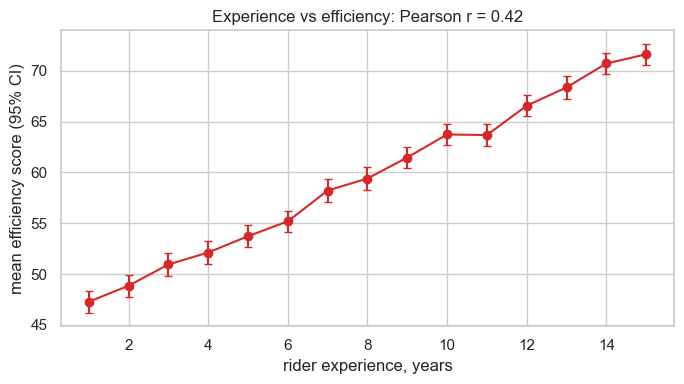

In [65]:
fig, ax = plt.subplots(figsize=(7, 4))
exp = delivered.groupby("delivery_partner_experience_years").delivery_efficiency_score.agg(["mean", "sem"])
ax.errorbar(exp.index, exp["mean"], yerr=1.96 * exp["sem"], marker="o", color="#d62828", capsize=3)
ax.set_xlabel("rider experience, years"); ax.set_ylabel("mean efficiency score (95% CI)")
ax.set_title(f"Experience vs efficiency: Pearson r = {pearson.statistic:.2f}")
fig.tight_layout(); fig.savefig(FIG + "05_rider_experience_efficiency.png", dpi=120)

In [66]:
exp['mean'].iloc[[0, -1]].round(1)

delivery_partner_experience_years
1     47.3
15    71.6
Name: mean, dtype: float64

Rider experience and efficiency have a moderate positive relationship: Pearson r = 0.42, Spearman 0.41, p < 0.001. Mean efficiency rises from 47.3 at 1 year to 71.6 at 15 years. This is correlation in synthetic data, not proof that training raises efficiency.

### Retention

In [67]:
orders_per_customer = clean.groupby("customer_id").size()
repeat_rate = (orders_per_customer > 1).mean()
round(repeat_rate, 4), round(orders_per_customer.mean(), 3), orders_per_customer.value_counts().sort_index().to_dict()

(0.6073,
 2.052,
 {1: 2870, 2: 2313, 3: 1345, 4: 519, 5: 201, 6: 42, 7: 17, 8: 1, 9: 1})

60.7% of customers ordered more than once. The average is 2.05 orders per customer, and 2,870 customers ordered only once.

In [68]:
first_month = clean.groupby("customer_id").order_month.min().rename("cohort_month")
activity = clean[["customer_id", "order_month"]].drop_duplicates().join(first_month, on="customer_id")
activity["months_since_first"] = activity.order_month - activity.cohort_month
cohort_counts = activity.pivot_table(index="cohort_month", columns="months_since_first", values="customer_id", aggfunc="nunique")
cohort = cohort_counts.div(cohort_counts[0], axis=0)
cohort.round(3).iloc[:, :7]

months_since_first,0,1,2,3,4,5,6
cohort_month,,,,,,,
1,1.0,0.133,0.118,0.122,0.128,0.129,0.133
2,1.0,0.129,0.114,0.115,0.138,0.152,0.130
3,1.0,0.130,0.143,0.131,0.110,0.146,0.120
4,1.0,0.136,0.132,0.124,0.129,0.127,0.131
5,1.0,0.115,0.109,0.157,0.118,0.159,0.115
6,1.0,0.164,0.139,0.135,0.148,0.148,0.143
7,1.0,0.146,0.135,0.145,0.102,0.125,NaN
8,1.0,0.124,0.098,0.117,0.110,NaN,NaN
9,1.0,0.146,0.183,0.115,NaN,NaN,NaN


In [69]:
cohort_long = cohort_counts.stack().rename("active").reset_index()
merged = retention_sql.merge(cohort_long, on=["cohort_month", "months_since_first"])
assert (merged.active_customers.astype(int) == merged.active.astype(int)).all() and len(merged) == len(retention_sql)
"pandas cohort table == sql/bigquery/06_retention.sql"

'pandas cohort table == sql/bigquery/06_retention.sql'

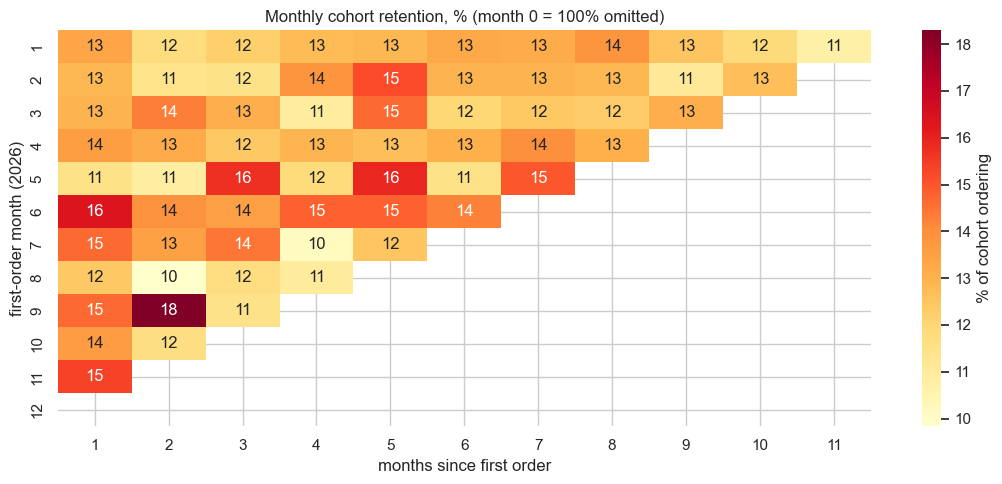

In [70]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(cohort.iloc[:, 1:] * 100, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "% of cohort ordering"}, ax=ax)
ax.set_title("Monthly cohort retention, % (month 0 = 100% omitted)")
ax.set_xlabel("months since first order"); ax.set_ylabel("first-order month (2026)")
fig.tight_layout(); fig.savefig(FIG + "06_cohort_retention.png", dpi=120)

In [71]:
m3 = cohort_counts[3].sum() / cohort_counts.loc[cohort_counts[3].notna(), 0].sum()
m1 = cohort_counts[1].sum() / cohort_counts.loc[cohort_counts[1].notna(), 0].sum()
round(m1, 4), round(m3, 4)

(0.1353, 0.1281)

Month-1 retention is 13.5% and month-3 retention is 12.8% (weighted across the cohorts that can reach month 3,
January to September). Retention is flat at about 12-13% per month after the first, with no decay curve. That is the signature of
customer IDs assigned at random to orders. Real cohorts decay, so this curve should not be used to forecast LTV.

### Findings

In [72]:
findings = pd.DataFrame([
    {"area": "Growth", "finding": f"GMV is flat: best month Aug SAR {monthly.gmv_sar.max():,.0f}, worst Apr SAR {monthly.gmv_sar.min():,.0f}, spread {spread:.1%}",
     "so_what": "No seasonality to plan around in this base; any real growth claim needs real dates",
     "next_step": "Re-run on live order dates and add Ramadan / Eid / payday markers"},
    {"area": "Growth", "finding": f"Dammam has {city.orders.max():,} orders ({city.gmv_share.max():.1%} of GMV); AOV gap across cities only SAR {city.aov_sar.max() - city.aov_sar.min():.2f}",
     "so_what": "Cities differ in volume, not basket, so city growth is an acquisition problem",
     "next_step": "Split city growth into new vs returning customers before budgeting acquisition"},
    {"area": "Promotions", "finding": f"Promo orders AOV SAR {promo.loc[True, 'aov_sar']:.2f} vs {promo.loc[False, 'aov_sar']:.2f} without (p = {promo_t.pvalue:.2f})",
     "so_what": "Promo codes do not lift basket size",
     "next_step": "Test promos on frequency / reactivation instead of basket size, with a holdout"},
    {"area": "Customers", "finding": f"Premium AOV SAR {segment.loc[True, 'aov_sar']:.2f} vs regular {segment.loc[False, 'aov_sar']:.2f} (+{segment.loc[True, 'aov_uplift_vs_regular']:.1%})",
     "so_what": "Premium customers are the highest-value segment per order",
     "next_step": "Size premium upgrade conversion and test a premium trial for high-frequency regular users"},
    {"area": "Delivery", "finding": f"Distance drives delivery time: r = {drivers['delivery_distance_km']:.2f}, {fit[0]:.1f} min per km; prep r = {drivers['preparation_time_minutes']:.2f}",
     "so_what": "Delivery radius and kitchen prep are the controllable levers, not weather",
     "next_step": "Simulate a tighter radius for >30 km orders and track prep time per restaurant"},
    {"area": "Delivery", "finding": f"{eta_breach.mean():.1%} of orders miss ETA but only {clean.delayed_delivery_flag.mean():.2%} are flagged delayed",
     "so_what": "The late flag understates lateness and does not respond to traffic, weather or distance",
     "next_step": "Agree one SLA definition with Logistics; report ETA breach next to the flag"},
    {"area": "Riders", "finding": f"Rider experience vs efficiency: Pearson r = {pearson.statistic:.2f} (p < 0.001)",
     "so_what": "Experienced riders are more efficient; new riders are the weak spot",
     "next_step": "Pair riders in their first year with high-efficiency zones and track the gap"},
    {"area": "Retention", "finding": f"Repeat rate {repeat_rate:.1%}, {orders_per_customer.mean():.2f} orders per customer, month-3 retention {m3:.1%}",
     "so_what": "Flat retention curve; most value is from repeat customers",
     "next_step": "Build an onboarding nudge for the 2,870 one-order customers and A/B it"},
    {"area": "Funnel", "finding": f"Checkout to delivered {1 - clean.cancellation_flag.mean():.2%}; cancellation {clean.cancellation_flag.mean():.2%}; no pre-checkout drop-off in the event data",
     "so_what": "Cancellation is the only funnel loss we can measure",
     "next_step": "Log browse sessions that do not convert so the top of the funnel is measurable"},
])
findings.to_csv("../reports/findings.csv", index=False)
findings

,area,finding,so_what,next_step
0,Growth,"GMV is flat: best month Aug SAR 498,021, worst...",No seasonality to plan around in this base; an...,Re-run on live order dates and add Ramadan / E...
1,Growth,"Dammam has 7,520 orders (50.3% of GMV); AOV ga...","Cities differ in volume, not basket, so city g...",Split city growth into new vs returning custom...
2,Promotions,Promo orders AOV SAR 445.78 vs 446.32 without ...,Promo codes do not lift basket size,Test promos on frequency / reactivation instea...
3,Customers,Premium AOV SAR 481.87 vs regular 431.97 (+11.6%),Premium customers are the highest-value segmen...,Size premium upgrade conversion and test a pre...
4,Delivery,"Distance drives delivery time: r = 0.86, 2.5 m...",Delivery radius and kitchen prep are the contr...,Simulate a tighter radius for >30 km orders an...
5,Delivery,47.8% of orders miss ETA but only 9.47% are fl...,The late flag understates lateness and does no...,Agree one SLA definition with Logistics; repor...
6,Riders,Rider experience vs efficiency: Pearson r = 0....,Experienced riders are more efficient; new rid...,Pair riders in their first year with high-effi...
7,Retention,"Repeat rate 60.7%, 2.05 orders per customer, m...",Flat retention curve; most value is from repea...,"Build an onboarding nudge for the 2,870 one-or..."
8,Funnel,Checkout to delivered 86.65%; cancellation 13....,Cancellation is the only funnel loss we can me...,Log browse sessions that do not convert so the...


In [73]:
kpi_monthly = (clean.assign(customer_type=np.where(clean.premium_customer_flag, "premium", "regular"),
                            delivered=~clean.cancellation_flag,
                            gmv_sar=np.where(clean.cancellation_flag, 0.0, clean.final_amount_paid_sar),
                            on_time=(~clean.cancellation_flag) & (~clean.delayed_delivery_flag),
                            delivery_min_delivered=np.where(clean.cancellation_flag, 0, clean.delivery_time_minutes))
               .groupby(["order_month", "city", "customer_type"])
               .agg(orders=("order_id", "size"), delivered=("delivered", "sum"), cancelled=("cancellation_flag", "sum"),
                    gmv_sar=("gmv_sar", "sum"), on_time=("on_time", "sum"), delivery_min_sum=("delivery_min_delivered", "sum"))
               .reset_index())
assert kpi_monthly.orders.sum() == 15000 and abs(kpi_monthly.gmv_sar.sum() - kpi_pandas.gmv_sar) < 0.01
kpi_monthly.to_csv("../reports/kpi_monthly.csv", index=False)
kpi_monthly.head()

,order_month,city,customer_type,orders,delivered,cancelled,gmv_sar,on_time,delivery_min_sum
0,1,Dammam,premium,186,155,31,75212.91,138,14289
1,1,Dammam,regular,452,393,59,171628.97,361,38182
2,1,Jeddah,premium,91,78,13,35333.03,72,7105
3,1,Jeddah,regular,242,201,41,85721.00,191,18590
4,1,Riyadh,premium,86,78,8,38107.86,66,7270


`kpi_monthly.csv` is additive (sums, not averages), so the dashboard can filter by month, city and customer type and re-derive every KPI without re-running the analysis.

## Step 7 - A/B test: free-delivery threshold SAR 75 (control) vs SAR 50 (treatment)

The design and limitations are recorded in `docs/experiment_design.md`. This is a retrospective portfolio
exercise after data exploration, not a prospectively registered experiment.
Unit of randomisation: customer (seeded assignment, 50/50). Primary metric: conversion = delivered orders / checkout sessions.
Guardrails: average delivery time and late rate must not get worse. Cancellation is reported, but in this data it
is exactly 1 - conversion, so it is not an independent guardrail. Secondary: revenue per user (delivered GMV per
assigned customer).

In [74]:
assignment = clean.groupby("customer_id").ab_group.first().value_counts().sort_index()
srm = stats.chisquare(assignment.values)
assignment.to_dict(), round(srm.pvalue, 4)

({'control': 3601, 'treatment': 3708}, 0.2107)

SRM check: 3,601 control vs 3,708 treatment customers, chi-square p = 0.21 > 0.05. The split is consistent with 50/50, so the test is valid to read.

In [75]:
baseline = 1 - clean.loc[clean.ab_group == "control", "cancellation_flag"].mean()
power = NormalIndPower()
n_guide = power.solve_power(proportion_effectsize(0.38, 0.35), alpha=0.05, power=0.8, ratio=1)
n_here = power.solve_power(proportion_effectsize(baseline + 0.03, baseline), alpha=0.05, power=0.8, ratio=1)
mde_here = proportion_effectsize(baseline + 0.03, baseline)
round(baseline, 4), int(np.ceil(n_guide)), int(np.ceil(n_here))

(0.8693, 4041, 1779)

With the guide's 35% baseline and a 3 pp MDE you need about 4,000 per group. The real baseline here is 86.9%, so a
3 pp lift needs about 1,800 sessions per group. There are about 7,400 checkout sessions per group, so the test is
powered. The power calculation is in sessions while randomisation is by customer, so the customer-level test
below is the robustness check for clustering.

In [76]:
min_basket = clean.order_value_sar.min()
min_basket, bool((clean.order_value_sar >= 75).all())

(375.0, True)

**Why the observed data cannot show a treatment effect.** The smallest basket is SAR 375 (the source floors baskets
at USD 100). Every order clears both SAR 50 and SAR 75, so free delivery qualifies identically in both arms.
`delivery_fee_sar` is still charged on 99.99% of orders, so the threshold was never applied to the data. The observed
comparison is therefore an **A/A test**. A real readout needs baskets below SAR 75, which this base does not have.

In [77]:
def ab_readout(df, label):
    rows = []
    g = {k: v for k, v in df.groupby("ab_group")}
    c, t = g["control"], g["treatment"]
    conv_c, conv_t = (~c.cancellation_flag).mean(), (~t.cancellation_flag).mean()
    table = [[(~c.cancellation_flag).sum(), c.cancellation_flag.sum()], [(~t.cancellation_flag).sum(), t.cancellation_flag.sum()]]
    chi2, p, _, _ = stats.chi2_contingency(table, correction=False)
    se = np.sqrt(conv_c * (1 - conv_c) / len(c) + conv_t * (1 - conv_t) / len(t))
    d = conv_t - conv_c
    rows.append(dict(metric="conversion (session)", role="primary", test="chi-square 2x2", control=conv_c, treatment=conv_t,
                     diff=d, ci_low=d - 1.96 * se, ci_high=d + 1.96 * se, p_value=p))

    per_cust = df.assign(delivered=~df.cancellation_flag,
                         revenue=np.where(df.cancellation_flag, 0.0, df.final_amount_paid_sar)) \
                 .groupby(["customer_id", "ab_group"]).agg(conv=("delivered", "mean"), revenue=("revenue", "sum")).reset_index()
    for metric, col, role in [("conversion (customer mean)", "conv", "robustness"), ("revenue per user, SAR", "revenue", "secondary")]:
        a = per_cust.loc[per_cust.ab_group == "control", col]; b = per_cust.loc[per_cust.ab_group == "treatment", col]
        w = stats.ttest_ind(b, a, equal_var=False)
        se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
        rows.append(dict(metric=metric, role=role, test="Welch t-test", control=a.mean(), treatment=b.mean(),
                         diff=b.mean() - a.mean(), ci_low=b.mean() - a.mean() - 1.96 * se, ci_high=b.mean() - a.mean() + 1.96 * se, p_value=w.pvalue))

    dc, dt = c[~c.cancellation_flag], t[~t.cancellation_flag]
    w = stats.ttest_ind(dt.delivery_time_minutes, dc.delivery_time_minutes, equal_var=False)
    se = np.sqrt(dc.delivery_time_minutes.var() / len(dc) + dt.delivery_time_minutes.var() / len(dt))
    d = dt.delivery_time_minutes.mean() - dc.delivery_time_minutes.mean()
    rows.append(dict(metric="avg delivery time, min", role="guardrail", test="Welch t-test", control=dc.delivery_time_minutes.mean(),
                     treatment=dt.delivery_time_minutes.mean(), diff=d, ci_low=d - 1.96 * se, ci_high=d + 1.96 * se, p_value=w.pvalue))
    lc, lt = dc.delayed_delivery_flag.mean(), dt.delayed_delivery_flag.mean()
    _, p, _, _ = stats.chi2_contingency([[dc.delayed_delivery_flag.sum(), (~dc.delayed_delivery_flag).sum()],
                                         [dt.delayed_delivery_flag.sum(), (~dt.delayed_delivery_flag).sum()]], correction=False)
    se = np.sqrt(lc * (1 - lc) / len(dc) + lt * (1 - lt) / len(dt))
    rows.append(dict(metric="late rate (delivered)", role="guardrail", test="chi-square 2x2", control=lc, treatment=lt,
                     diff=lt - lc, ci_low=lt - lc - 1.96 * se, ci_high=lt - lc + 1.96 * se, p_value=p))
    cc, ct = c.cancellation_flag.mean(), t.cancellation_flag.mean()
    rows.append(dict(metric="cancellation rate", role="guardrail (= 1 - conversion)", test="mirror of primary", control=cc, treatment=ct,
                     diff=ct - cc, ci_low=-(rows[0]["ci_high"]), ci_high=-(rows[0]["ci_low"]), p_value=rows[0]["p_value"]))
    out = pd.DataFrame(rows)
    out.insert(0, "data", label)
    return out

In [78]:
observed = ab_readout(clean, "observed (A/A)")
observed.round(4)

,data,metric,role,test,control,treatment,diff,ci_low,ci_high,p_value
0,observed (A/A),conversion (session),primary,chi-square 2x2,0.8693,0.8637,-0.0055,-0.0164,0.0054,0.3208
1,observed (A/A),conversion (customer mean),robustness,Welch t-test,0.8683,0.8621,-0.0061,-0.0187,0.0064,0.3365
2,observed (A/A),"revenue per user, SAR",secondary,Welch t-test,797.7804,788.8601,-8.9203,-32.2591,14.4184,0.4538
3,observed (A/A),"avg delivery time, min",guardrail,Welch t-test,93.8132,93.9428,0.1296,-1.0222,1.2814,0.8254
4,observed (A/A),late rate (delivered),guardrail,chi-square 2x2,0.0929,0.0969,0.0039,-0.0061,0.0140,0.4425
5,observed (A/A),cancellation rate,guardrail (= 1 - conversion),mirror of primary,0.1307,0.1363,0.0055,-0.0054,0.0164,0.3208


In [79]:
assert np.isclose(observed.loc[0, "control"], ab_sql.loc[0, "conversion"], atol=1e-4)
assert np.isclose(observed.loc[0, "treatment"], ab_sql.loc[1, "conversion"], atol=1e-4)
"observed readout matches sql/bigquery/07_ab_scorecard.sql"

'observed readout matches sql/bigquery/07_ab_scorecard.sql'

Observed data: conversion 86.93% control vs 86.37% treatment, a -0.56 pp gap whose CI includes zero. That is what an A/A test should show, and it confirms the pipeline does not invent effects.

In [80]:
# SIMULATED EFFECT -- for demonstration. Not observed behaviour.
rng = np.random.default_rng(42)
sim = clean.copy()
treat = sim.ab_group == "treatment"
n_flip = int(round(0.03 * treat.sum()))
flip_ids = rng.choice(sim.index[treat & sim.cancellation_flag], size=n_flip, replace=False)
sim.loc[flip_ids, "cancellation_flag"] = False
n_flip, round((~sim.loc[treat, "cancellation_flag"]).mean() - (~clean.loc[treat, "cancellation_flag"]).mean(), 4)

(228, 0.03)

**SIMULATED EFFECT, for demonstration.** 228 treatment checkout sessions (3% of the arm) are switched from
cancelled to delivered with seed 42, which lifts treatment conversion by exactly +3 pp
over its own observed rate (+2.44 pp net of control, because the arms started 0.56 pp apart). Revenue per user is *not*
separately inflated (the guide suggested +SAR 2). It moves only because those orders now count as delivered, so all
metrics stay internally consistent. Delivery time and late rate are left as recorded.

In [81]:
simulated = ab_readout(sim, "SIMULATED (+3 pp)")
simulated.round(4)

,data,metric,role,test,control,treatment,diff,ci_low,ci_high,p_value
0,SIMULATED (+3 pp),conversion (session),primary,chi-square 2x2,0.8693,0.8937,0.0244,0.0141,0.0348,0.0000
1,SIMULATED (+3 pp),conversion (customer mean),robustness,Welch t-test,0.8683,0.8912,0.0230,0.0110,0.0349,0.0002
2,SIMULATED (+3 pp),"revenue per user, SAR",secondary,Welch t-test,797.7804,815.8055,18.0251,-5.4205,41.4706,0.1319
3,SIMULATED (+3 pp),"avg delivery time, min",guardrail,Welch t-test,93.8132,94.1029,0.2897,-0.8527,1.4322,0.6191
4,SIMULATED (+3 pp),late rate (delivered),guardrail,chi-square 2x2,0.0929,0.0978,0.0048,-0.0052,0.0148,0.3459
5,SIMULATED (+3 pp),cancellation rate,guardrail (= 1 - conversion),mirror of primary,0.1307,0.1063,-0.0244,-0.0348,-0.0141,0.0000


In [82]:
seg_rows = []
for dim in ["city", "premium_customer_flag"]:
    for value, part in sim.groupby(dim):
        r = ab_readout(part, "SIMULATED (+3 pp)").iloc[0]
        seg_rows.append({"segment": f"{dim}={value}", "control": r.control, "treatment": r.treatment, "diff": r["diff"],
                         "ci_low": r.ci_low, "ci_high": r.ci_high, "p_value": r.p_value})
segments = pd.DataFrame(seg_rows)
segments.round(4)

,segment,control,treatment,diff,ci_low,ci_high,p_value
0,city=Dammam,0.8766,0.8921,0.0155,0.0010,0.0299,0.0359
1,city=Jeddah,0.8597,0.8992,0.0395,0.0187,0.0603,0.0002
2,city=Riyadh,0.8642,0.8915,0.0274,0.0063,0.0484,0.0107
3,premium_customer_flag=False,0.8655,0.8937,0.0282,0.0159,0.0405,0.0000
4,premium_customer_flag=True,0.8788,0.8938,0.0150,-0.0041,0.0341,0.1248


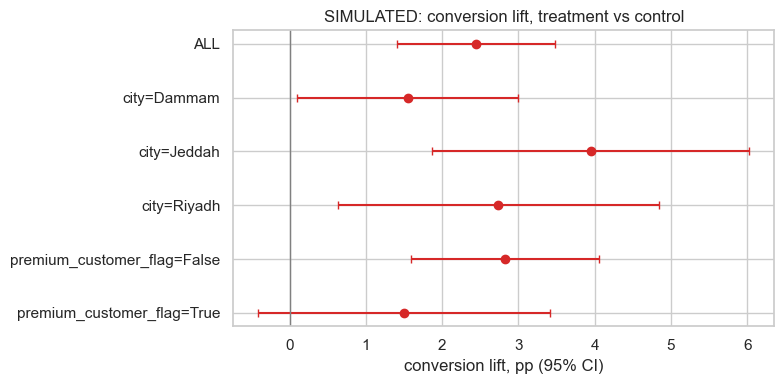

In [83]:
fig, ax = plt.subplots(figsize=(8, 4))
plot = pd.concat([simulated.iloc[[0]].assign(segment="ALL"), segments], ignore_index=True)
y = np.arange(len(plot))[::-1]
ax.errorbar(plot["diff"] * 100, y, xerr=[(plot["diff"] - plot.ci_low) * 100, (plot.ci_high - plot["diff"]) * 100],
            fmt="o", color="#d62828", capsize=3)
ax.axvline(0, color="grey", lw=1); ax.set_yticks(y); ax.set_yticklabels(plot.segment)
ax.set_xlabel("conversion lift, pp (95% CI)"); ax.set_title("SIMULATED: conversion lift, treatment vs control")
fig.tight_layout(); fig.savefig(FIG + "07_ab_conversion_lift_simulated.png", dpi=120)

In [84]:
def verdict(readout):
    prim = readout.iloc[0]
    guard = readout[readout.role == "guardrail"]
    guard_bad = ((guard.ci_low > 0) & (guard.p_value < 0.05)).any()
    if prim.p_value < 0.05 and prim.ci_low > 0 and not guard_bad:
        return "LAUNCH", "primary lift is significant with CI above zero and no guardrail got significantly worse"
    if prim.p_value < 0.05 and prim.ci_high < 0:
        return "DO NOT LAUNCH", "conversion got significantly worse"
    if guard_bad:
        return "REVISE AND RETEST", "primary moved but a guardrail got significantly worse"
    return "REVISE AND RETEST", "no significant change in conversion; redesign so the threshold can bind"

v_obs, v_sim = verdict(observed), verdict(simulated)
v_obs, v_sim

(('REVISE AND RETEST',
  'no significant change in conversion; redesign so the threshold can bind'),
 ('LAUNCH',
  'primary lift is significant with CI above zero and no guardrail got significantly worse'))

In [85]:
ab_results = pd.concat([observed, simulated], ignore_index=True)
ab_results["verdict"] = np.where(ab_results.data.str.startswith("observed"), v_obs[0], v_sim[0])
ab_results.loc[len(ab_results)] = {"data": "SRM check", "metric": "customers per arm", "role": "validity", "test": "chi-square 50/50",
                                   "control": assignment["control"], "treatment": assignment["treatment"],
                                   "diff": assignment["treatment"] - assignment["control"], "ci_low": np.nan, "ci_high": np.nan,
                                   "p_value": srm.pvalue, "verdict": "valid" if srm.pvalue > 0.05 else "INVALID"}
segments.assign(data="SIMULATED (+3 pp)", metric="conversion by segment").to_csv("../reports/ab_segments.csv", index=False)
ab_results.to_csv("../reports/ab_results.csv", index=False)
ab_results.round(4)

,data,metric,role,test,control,treatment,diff,ci_low,ci_high,p_value,verdict
0,observed (A/A),conversion (session),primary,chi-square 2x2,0.8693,0.8637,-0.0055,-0.0164,0.0054,0.3208,REVISE AND RETEST
1,observed (A/A),conversion (customer mean),robustness,Welch t-test,0.8683,0.8621,-0.0061,-0.0187,0.0064,0.3365,REVISE AND RETEST
2,observed (A/A),"revenue per user, SAR",secondary,Welch t-test,797.7804,788.8601,-8.9203,-32.2591,14.4184,0.4538,REVISE AND RETEST
3,observed (A/A),"avg delivery time, min",guardrail,Welch t-test,93.8132,93.9428,0.1296,-1.0222,1.2814,0.8254,REVISE AND RETEST
4,observed (A/A),late rate (delivered),guardrail,chi-square 2x2,0.0929,0.0969,0.0039,-0.0061,0.0140,0.4425,REVISE AND RETEST
5,observed (A/A),cancellation rate,guardrail (= 1 - conversion),mirror of primary,0.1307,0.1363,0.0055,-0.0054,0.0164,0.3208,REVISE AND RETEST
6,SIMULATED (+3 pp),conversion (session),primary,chi-square 2x2,0.8693,0.8937,0.0244,0.0141,0.0348,0.0000,LAUNCH
7,SIMULATED (+3 pp),conversion (customer mean),robustness,Welch t-test,0.8683,0.8912,0.0230,0.0110,0.0349,0.0002,LAUNCH
8,SIMULATED (+3 pp),"revenue per user, SAR",secondary,Welch t-test,797.7804,815.8055,18.0251,-5.4205,41.4706,0.1319,LAUNCH
9,SIMULATED (+3 pp),"avg delivery time, min",guardrail,Welch t-test,93.8132,94.1029,0.2897,-0.8527,1.4322,0.6191,LAUNCH


### Verdict

* **Observed data (A/A): REVISE AND RETEST.** No significant conversion change, which is expected because every basket already qualifies for free delivery under both thresholds. Rerun on a population that has baskets between SAR 50 and SAR 75.
* **Simulated +3 pp effect: LAUNCH.** Conversion +2.44 pp (95% CI +1.41 to +3.48 pp, p < 0.001; customer-level check +2.30 pp, p < 0.001). Guardrails flat: delivery time +0.29 min (p = 0.62), late rate +0.48 pp (p = 0.35). Revenue per user +SAR 18.03 is **not** significant (CI -5.42 to +41.47, p = 0.13), so the launch case rests on conversion, not revenue. The premium segment alone is not significant (+1.50 pp, p = 0.12). This verdict is a demonstration of the decision rule on simulated data, not evidence about real customers.

In [86]:
summary = pd.Series({
    "orders": len(clean), "customers": clean.customer_id.nunique(), "gmv_sar": round(kpi_pandas.gmv_sar, 2),
    "aov_sar": round(kpi_pandas.aov_sar, 2), "cancellation_rate": round(kpi_pandas.cancellation_rate, 4),
    "on_time_rate": round(kpi_pandas.on_time_rate, 4), "avg_delivery_min": round(kpi_pandas.avg_delivery_min, 2),
    "repeat_rate": round(repeat_rate, 4), "month3_retention": round(m3, 4), "srm_p": round(srm.pvalue, 4),
    "sim_conversion_lift_pp": round(simulated.loc[0, "diff"] * 100, 2), "sim_conversion_p": simulated.loc[0, "p_value"],
    "sim_rpu_diff_sar": round(simulated.loc[2, "diff"], 2), "sim_rpu_p": round(simulated.loc[2, "p_value"], 4),
    "verdict_observed": v_obs[0], "verdict_simulated": v_sim[0],
})
summary.to_json("../reports/headline_metrics.json", indent=2)
summary

orders                                15000
customers                              7309
gmv_sar                          5797900.58
aov_sar                               446.1
cancellation_rate                    0.1335
on_time_rate                         0.9051
avg_delivery_min                      93.88
repeat_rate                          0.6073
month3_retention                     0.1281
srm_p                                0.2107
sim_conversion_lift_pp                 2.44
sim_conversion_p                   0.000004
sim_rpu_diff_sar                      18.03
sim_rpu_p                            0.1319
verdict_observed          REVISE AND RETEST
verdict_simulated                    LAUNCH
dtype: object

## Limitations

* Synthetic base adapted to Saudi Arabia; nothing here describes real customers of a company.
* AOV of SAR 446 comes from USD baskets floored at 100 and converted at 3.75. It is not a typical Saudi basket.
* Seeded IDs and dates: weekday and day of month do not agree, customers span cities, and retention is flat.
* Funnel events are generated 4 per order, so pre-checkout drop-off cannot be measured.
* The A/B effect is simulated. The observed comparison is an A/A test because no basket is under SAR 75.
* BigQuery SQL was checked in DuckDB and the Redshift port in PostgreSQL 16; neither ran on the live cloud service.